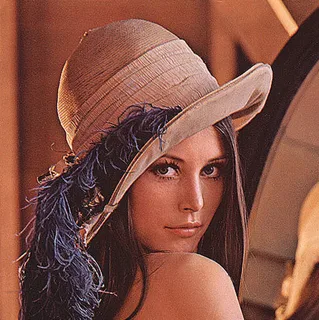

In [1]:
from PIL import Image
import struct
import ctypes

img = Image.open('lena.png')
(w, h) = img.size[0:2]
pix = img.load()
buff = ctypes.create_string_buffer(4 * w * h)
offset = 0
for j in range(h):
	for i in range(w):
		r = bytes((pix[i, j][0],))
		g = bytes((pix[i, j][1],))
		b = bytes((pix[i, j][2],))
		a = bytes((255,))
		struct.pack_into('cccc', buff, offset, r, g, b, a)
		offset += 4
out = open('in.data', 'wb')
out.write(struct.pack('ii', w, h))
out.write(buff.raw)
out.close()

display(img)

In [14]:
from PIL import Image
import struct
import ctypes

TARGET = 5000

img = Image.open('lena.png').convert('RGBA')
img = img.resize((TARGET, TARGET), Image.LANCZOS)

w, h = img.size
pix = img.load()

buff = ctypes.create_string_buffer(4 * w * h)
offset = 0
for j in range(h):
    for i in range(w):
        r, g, b, a = pix[i, j]
        struct.pack_into('cccc', buff, offset,
                         bytes((r,)), bytes((g,)), bytes((b,)), bytes((a,)))
        offset += 4

with open('in_5000.data', 'wb') as out:
    out.write(struct.pack('ii', w, h))
    out.write(buff.raw)

In [2]:
%%writefile lab3.cu

#include <iostream>
#include <cmath>
#include <iomanip>
#include <vector>
#include <string>
#include <cstring>
#include <fstream>
#include <cstdlib>

#define CSC(call) \
do { \
    cudaError_t res = call; \
    if (res != cudaSuccess) { \
        fprintf(stderr, "ERROR in %s:%d. Message: %s\n", \
            __FILE__, __LINE__, cudaGetErrorString(res)); \
        exit(0); \
    } \
} while(0)


__constant__ float avg_norm[32][3];

__global__ void kernel(uchar4 *data, int w, int h, int nc) {
    int idx = blockDim.x * blockIdx.x + threadIdx.x;
    int offset = blockDim.x * gridDim.x;

    for (int i = idx; i < w * h; i += offset) {
        uchar4 p = data[i];

        int best = 0;
        float best_val = p.x * avg_norm[0][0] + p.y * avg_norm[0][1] + p.z * avg_norm[0][2];
        for (int j = 1; j < nc; ++j) {
            float val = p.x * avg_norm[j][0] + p.y * avg_norm[j][1] + p.z * avg_norm[j][2];
            if (val > best_val) {
                best_val = val;
                best = j;
            }
        }

        data[i].w = (unsigned char)best;
    }
}


int main(int argc, char* argv[]) {
    int blocksPerGrid = 1024; // База
    int threadsPerBlock = 1024;
    std::string filename = "";

    for (int i = 1; i < argc; ++i) {
        if (std::strcmp(argv[i], "-f") == 0 && i + 1 < argc) {
            filename = argv[++i];
        } else if (std::strcmp(argv[i], "-grid") == 0 && i + 1 < argc) {
            blocksPerGrid = std::atoi(argv[++i]);
        } else if (std::strcmp(argv[i], "-block") == 0 && i + 1 < argc) {
            threadsPerBlock = std::atoi(argv[++i]);
        }
    }




    char in_path[256], out_path[256];
    scanf("%s %s", in_path, out_path);

    int nc;
    scanf("%d", &nc);

    int w, h;
    FILE *fp = fopen(in_path, "rb");
    fread(&w, sizeof(int), 1, fp);
    fread(&h, sizeof(int), 1, fp);
    uchar4 *data = (uchar4 *)malloc(sizeof(uchar4) * w * h);
    fread(data, sizeof(uchar4), w * h, fp);
    fclose(fp);

    float avg_host[32][3];
    for (int j = 0; j < nc; ++j) {
        int np;
        scanf("%d", &np);
        double sr = 0.0, sg = 0.0, sb = 0.0;
        for (int k = 0; k < np; ++k) {
            int px, py;
            scanf("%d %d", &px, &py);
            uchar4 p = data[py * w + px];
            sr += p.x;
            sg += p.y;
            sb += p.z;
        }
        double ar = sr / np, ag = sg / np, ab = sb / np;
        double len = sqrt(ar * ar + ag * ag + ab * ab);
        
        avg_host[j][0] = (float)(ar / len);
        avg_host[j][1] = (float)(ag / len);
        avg_host[j][2] = (float)(ab / len);
    }
    CSC(cudaMemcpyToSymbol(avg_norm, avg_host, sizeof(avg_host)));

    uchar4 *dev_data;
    CSC(cudaMalloc(&dev_data, sizeof(uchar4) * w * h));
    CSC(cudaMemcpy(dev_data, data, sizeof(uchar4) * w * h, cudaMemcpyHostToDevice));

    cudaEvent_t start, stop;
    CSC(cudaEventCreate(&start));
    CSC(cudaEventCreate(&stop));

    CSC(cudaEventRecord(start));

    kernel<<< blocksPerGrid, threadsPerBlock >>>(dev_data, w, h, nc);

    CSC(cudaEventRecord(stop));
    CSC(cudaEventSynchronize(stop));
    CSC(cudaGetLastError());

    float time_ms = 0.0f;
    CSC(cudaEventElapsedTime(&time_ms, start, stop));

    CSC(cudaEventDestroy(start));
    CSC(cudaEventDestroy(stop));

    fprintf(stderr, "TIME_MS: %f\n", time_ms);

    CSC(cudaMemcpy(data, dev_data, sizeof(uchar4) * w * h, cudaMemcpyDeviceToHost));

    CSC(cudaFree(dev_data));

    fp = fopen(out_path, "wb");
    fwrite(&w, sizeof(int), 1, fp);
    fwrite(&h, sizeof(int), 1, fp);
    fwrite(data, sizeof(uchar4), w * h, fp);
    fclose(fp);

    free(data);
    return 0;
}


Overwriting lab3.cu


In [3]:
%%writefile lab3cpu.cpp

#include <iostream>
#include <cmath>
#include <iomanip>
#include <vector>
#include <string>
#include <cstring>
#include <fstream>
#include <cstdlib>
#include <chrono>


struct uchar4 {
    uint8_t x, y, z, w;
};

int main(int argc, char* argv[]) {
    int blocksPerGrid = 1024;
    int threadsPerBlock = 1024;
    std::string filename = "";

    for (int i = 1; i < argc; ++i) {
        if (std::strcmp(argv[i], "-f") == 0 && i + 1 < argc) {
            filename = argv[++i];
        } 
        else if (std::strcmp(argv[i], "-grid") == 0 && i + 1 < argc) {
            blocksPerGrid = std::atoi(argv[++i]);
        } 
        else if (std::strcmp(argv[i], "-block") == 0 && i + 1 < argc) {
            threadsPerBlock = std::atoi(argv[++i]);
        }
    }

    char in_path[256], out_path[256];
    scanf("%s %s", in_path, out_path);

    int nc;
    scanf("%d", &nc);

    int w, h;
    FILE *fp = fopen(in_path, "rb");
    fread(&w, sizeof(int), 1, fp);
    fread(&h, sizeof(int), 1, fp);
    uchar4 *data = (uchar4 *)malloc(sizeof(uchar4) * w * h);
    fread(data, sizeof(uchar4), w * h, fp);
    fclose(fp);

    float avg_norm[32][3];
    for (int j = 0; j < nc; ++j) {
        int np;
        scanf("%d", &np);
        double sr = 0.0, sg = 0.0, sb = 0.0;
        for (int k = 0; k < np; ++k) {
            int px, py;
            scanf("%d %d", &px, &py);
            uchar4 p = data[py * w + px];
            sr += p.x;
            sg += p.y;
            sb += p.z;
        }
        double ar = sr / np, ag = sg / np, ab = sb / np;
        double len = sqrt(ar * ar + ag * ag + ab * ab);
        
        avg_norm[j][0] = (float)(ar / len);
        avg_norm[j][1] = (float)(ag / len);
        avg_norm[j][2] = (float)(ab / len);
    }

    uchar4 *out = (uchar4 *)malloc(sizeof(uchar4) * w * h);

    auto start = std::chrono::high_resolution_clock::now();

    for (int y = 0; y < h; ++y) {
        for (int x = 0; x < w; ++x) {
            uchar4 p = data[y * w + x];

            int best = 0;
            float best_val = p.x * avg_norm[0][0] + p.y * avg_norm[0][1] + p.z * avg_norm[0][2];
            for (int j = 1; j < nc; ++j) {
                float val = p.x * avg_norm[j][0] + p.y * avg_norm[j][1] + p.z * avg_norm[j][2];
                
                if (val > best_val) {
                    best_val = val;
                    best = j;
                }
            }

            out[y * w + x] = uchar4{p.x, p.y, p.z, (uint8_t)best};
        }
    }

    auto end = std::chrono::high_resolution_clock::now();

    std::chrono::duration elapsed = end - start;
    double time_ms = elapsed.count();

    std::cerr << "TIME_MS: " << time_ms << "\n";

    fp = fopen(out_path, "wb");
    fwrite(&w, sizeof(int), 1, fp);
    fwrite(&h, sizeof(int), 1, fp);
    fwrite(out, sizeof(uchar4), w * h, fp);
    fclose(fp);

    free(data);
    free(out);
    return 0;
}

Overwriting lab3cpu.cpp


In [4]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Fri_Nov__3_17:51:05_Pacific_Daylight_Time_2023
Cuda compilation tools, release 12.3, V12.3.103
Build cuda_12.3.r12.3/compiler.33492891_0


In [5]:
import subprocess
import re
import os
import random
import pandas as pd
import struct
from PIL import Image
from IPython.display import display
import cv2
import matplotlib.pyplot as plt

In [6]:
print("\nКомпиляция lab3.cu...")
compile_res = subprocess.run(
    [
        "nvcc",
        "-allow-unsupported-compiler",
        "-Xcompiler",
        "-D_ALLOW_COMPILER_AND_STL_VERSION_MISMATCH", # иначе не работает....
        "-O3",
        "lab3.cu",
        "-o",
        "lab3.exe",
    ],
    capture_output=True,
)

stdout_msg = compile_res.stdout.decode("cp1251", errors="replace")
stderr_msg = compile_res.stderr.decode("cp1251", errors="replace")

if compile_res.returncode != 0:
    print("Ошибка компиляции:")
    if stdout_msg:
        print("STDOUT:\n", stdout_msg)
    if stderr_msg:
        print("STDERR:\n", stderr_msg)
else:
    print("Компиляция успешно завершена (lab3.exe создан).")


Компиляция lab3.cu...
Компиляция успешно завершена (lab3.exe создан).


In [7]:
import subprocess

vcvars_path = r"C:\Program Files (x86)\Microsoft Visual Studio\2022\BuildTools\VC\Auxiliary\Build\vcvars64.bat"

cmd = f'"{vcvars_path}" && cl lab3cpu.cpp /EHsc /std:c++17 /Fe:lab3cpu.exe'

compile_res = subprocess.run(
    cmd,
    shell=True,
    capture_output=True,
)

stdout_msg = compile_res.stdout.decode("cp1251", errors="replace")
stderr_msg = compile_res.stderr.decode("cp1251", errors="replace")

if compile_res.returncode != 0:
    print("Ошибка компиляции:")
    if stdout_msg:
        print("STDOUT:\n", stdout_msg)
    if stderr_msg:
        print("STDERR:\n", stderr_msg)
else:
    print("Компиляция успешно завершена (lab3cpu.exe создан).")

Компиляция успешно завершена (lab3cpu.exe создан).


In [8]:
res = subprocess.run(
    [r".\lab3.exe"],
    input="04.data out.data\n2\n4 1 2 1 0 2 2 2 1\n4 0 0 0 1 1 1 2 0\n",
    text=True,
    capture_output=True,
    encoding="cp1251",
    errors="replace",
)
print(res.stderr)

TIME_MS: 0.024576



In [9]:

import filecmp
print(filecmp.cmp("out.data", "04_out.data", shallow=False))

True


In [10]:
with open("out.data", "rb") as f:
    w, h = struct.unpack("ii", f.read(8))
    raw_data = f.read()

img = Image.frombytes("RGBA", (w, h), raw_data)
display(img)

In [12]:
from tqdm import tqdm

In [23]:
configs = [
    #(1, 1),
    (1, 32),
    (1, 64),
    (1, 128),
    (1, 256),
    (1, 512),
    (16, 16),
    (16, 32),
    (16, 64),
    (16, 128),
    (16, 256),
    (16, 512),
    (32, 32),
    (32, 64),
    (32, 128),
    (32, 256),
    (32, 512),
    (64, 64),
    (64, 128),
    (32, 256),
    (128, 128),
    (128, 256),
    (128, 512),
    (512, 512),
    (1024, 1024),
    #(2048, 2048)
]

results = []

for fname in ["in.data", "in_5000.data"]:
    for grid, block in tqdm(configs):
        cmd = [r".\lab3.exe", "-grid", str(grid), "-block", str(block)]

        t_gpu = 0.0
        for repeat in range(3):
            proc = subprocess.run(
                cmd,
                input=f"{fname} out.data\n",
                stdout=subprocess.DEVNULL,
                stderr=subprocess.PIPE,
                text=True,
                encoding="cp1251",
                errors="replace",
            )

            match = re.search(r"TIME_MS:\s*([\d\.]+)", proc.stderr)
            t_gpu_t = float(match.group(1)) if match else None
            t_gpu += t_gpu_t

        results.append(
            {
                "Файл / Набор": fname,
                "Grid": grid,
                "Block": block,
                "Конфигурация": f"<<< {grid}, {block} >>>",
                "Время GPU (мс)": t_gpu/3.0,
            }
        )

df = pd.DataFrame(results)
df

100%|██████████| 24/24 [00:25<00:00,  1.08s/it]


,Файл / Набор,Grid,Block,Конфигурация,Время GPU (мс)
0,in.data,1,32,"<<< 1, 32 >>>",0.054251
1,in.data,1,64,"<<< 1, 64 >>>",0.034133
2,in.data,1,128,"<<< 1, 128 >>>",0.029696
3,in.data,1,256,"<<< 1, 256 >>>",0.030037
4,in.data,1,512,"<<< 1, 512 >>>",0.030037
5,in.data,16,16,"<<< 16, 16 >>>",0.018421
6,in.data,16,32,"<<< 16, 32 >>>",0.016043
7,in.data,16,64,"<<< 16, 64 >>>",0.015360
8,in.data,16,128,"<<< 16, 128 >>>",0.015019
9,in.data,16,256,"<<< 16, 256 >>>",0.014677


In [24]:

results = []

for fname in ["in.data", "in_5000.data"]:
    cmd = [r".\lab3cpu.exe"]

    t_gpu = 0.0
    for repeat in range(3):
        proc = subprocess.run(
            cmd,
            input=f"{fname} out.data\n",
            stdout=subprocess.DEVNULL,
            stderr=subprocess.PIPE,
            text=True,
            encoding="cp1251",
            errors="replace",
        )

        match = re.search(r"TIME_MS:\s*([\d\.]+)", proc.stderr)
        t_gpu_t = float(match.group(1)) if match else None
        t_gpu += t_gpu_t

    results.append(
        {
            "Файл / Набор": fname,
            "Grid": None,
            "Block": None,
            "Конфигурация": f"cpu",
            "Время (мс)": t_gpu/3.0,
        }
    )

df_cpu = pd.DataFrame(results)
df_cpu

,Файл / Набор,Grid,Block,Конфигурация,Время (мс)
0,in.data,None,None,cpu,520300.336333
1,in_5000.data,None,None,cpu,1.678700


In [ ]:
df_cpu.iloc[0]["Время (мс)"]

Файл / Набор          in.data
Grid                     None
Block                    None
Конфигурация              cpu
Время (мс)      520300.336333
Name: 0, dtype: object

In [25]:
df["Ускорение"] = df["Файл / Набор"].map(df_cpu.set_index("Файл / Набор")["Время (мс)"]) / df["Время GPU (мс)"]
df

,Файл / Набор,Grid,Block,Конфигурация,Время GPU (мс),Ускорение
0,in.data,1,32,"<<< 1, 32 >>>",0.054251,9.590672e+06
1,in.data,1,64,"<<< 1, 64 >>>",0.034133,1.524317e+07
2,in.data,1,128,"<<< 1, 128 >>>",0.029696,1.752089e+07
3,in.data,1,256,"<<< 1, 256 >>>",0.030037,1.732179e+07
4,in.data,1,512,"<<< 1, 512 >>>",0.030037,1.732179e+07
5,in.data,16,16,"<<< 16, 16 >>>",0.018421,2.824445e+07
6,in.data,16,32,"<<< 16, 32 >>>",0.016043,3.243228e+07
7,in.data,16,64,"<<< 16, 64 >>>",0.015360,3.387372e+07
8,in.data,16,128,"<<< 16, 128 >>>",0.015019,3.464358e+07
9,in.data,16,256,"<<< 16, 256 >>>",0.014677,3.544924e+07


In [18]:
%%writefile info.cu
#include <stdio.h>

int main() {
	int deviceCount;
	cudaDeviceProp devProp;
	cudaGetDeviceCount(&deviceCount);
	printf("Found %d devices\n", deviceCount);
	for(int device = 0;device < deviceCount;device++) {
		cudaGetDeviceProperties(&devProp, device);
		printf("Device %d\n", device);
		printf("Compute capability      : %d.%d\n", devProp.major, devProp.minor);
		printf("Name                    : %s\n", devProp.name);
		printf("Total Global Memory     : %zu\n", devProp.totalGlobalMem);
		printf("Shared memory per block : %zu\n", devProp.sharedMemPerBlock);
		printf("Registers per block     : %d\n", devProp.regsPerBlock);
		printf("Warp size               : %d\n", devProp.warpSize);
		printf("Max threads per block   : (%d, %d, %d)\n", devProp.maxThreadsDim[0], devProp.maxThreadsDim[1], devProp.maxThreadsDim[2]);
		printf("Max block   : (%d, %d, %d)\n", devProp.maxGridSize[0], devProp.maxGridSize[1], devProp.maxGridSize[2]);
		printf("Total constant memory   : %zu\n", devProp.totalConstMem);
		printf("Multiprocessors count   : %d\n", devProp.multiProcessorCount);
	}
	return 0;
}

Writing info.cu


UsageError: Cell magic `%%shell` not found.
